# 워밍업 — 소프트맥스 맛보기 🎲

웹 챕터 **"소프트맥스 맛보기"** 와 짝을 이루는 Python 실습입니다.
웹에서 슬라이더로 잡은 "감"을, 여기서는 **직접 계산**으로 확인합니다.

준비물: `pip install -r requirements.txt`

> 🤖 **AI 튜터**: 아래 셀을 실행하면 웹앱처럼 화면 오른쪽 아래에 🤖 버튼이 생깁니다.
> 버튼을 누르면 채팅창이 열리고, 어디를 스크롤해도 그 자리에 떠 있어요. 막히면 언제든 질문하세요.
> (로컬 Ollama 필요. 꺼져 있으면 켜는 방법이 안내되고, 튜터 없이도 학습에는 지장 없습니다.)

In [ ]:
# 🤖 AI 튜터 — 실행하면 오른쪽 아래에 🤖 버튼이 떠요
from tutor import chat

chat('sample')

## 1. 점수(로짓)와 후보 단어

"오늘 날씨가 정말 ___" 다음에 올 단어 후보 4개와, 모델이 매긴 **점수(로짓)** 입니다.
점수는 음수도, 큰 양수도 될 수 있습니다.

In [1]:
import numpy as np

labels = ['좋다', '춥다', '덥다', '사과']
logits = np.array([3.0, 1.5, 1.0, -2.0])   # 각 단어의 점수(로짓)
for w, z in zip(labels, logits):
    print(f'{w}: 점수 {z:+.1f}')

좋다: 점수 +3.0
춥다: 점수 +1.5
덥다: 점수 +1.0
사과: 점수 -2.0


## 2. 소프트맥스 공식

$$\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

내 점수의 지수를, 모두의 지수를 더한 값으로 나눕니다.

> 💡 **수치 안정화**: 점수가 크면 `e^z` 가 폭발하므로, 먼저 **최댓값을 빼고** 계산합니다.
> 빼도 결과는 똑같습니다(분자·분모에서 약분되니까).

In [2]:
def softmax(z):
    z = np.asarray(z, dtype=float)
    z = z - z.max()          # 수치 안정화: 최댓값 빼기 (결과 불변)
    exp = np.exp(z)          # 지수 — 항상 양수
    return exp / exp.sum()   # 정규화 — 합이 1이 되게 나누기

probs = softmax(logits)
for w, p in zip(labels, probs):
    print(f'{w}: 확률 {p*100:5.1f}%')

print('합계:', probs.sum())   # 항상 1.0
print('LLM이 고를 단어 →', labels[int(np.argmax(probs))])

좋다: 확률  73.2%
춥다: 확률  16.3%
덥다: 확률   9.9%
사과: 확률   0.5%
합계: 0.9999999999999999
LLM이 고를 단어 → 좋다


## 3. 막대로 보기

왼쪽은 **점수(로짓)**, 오른쪽은 소프트맥스가 만든 **확률**입니다.
웹 실험실에서 본 그 막대와 같은 것입니다.

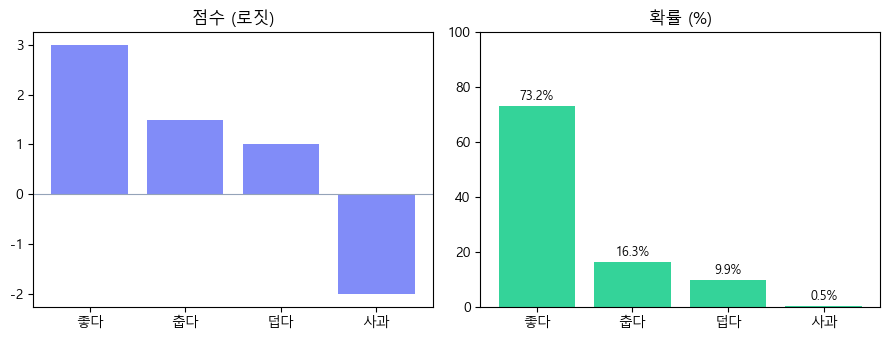

In [3]:
import matplotlib.pyplot as plt

# 한글 폰트 설정 (안 하면 한글 라벨이 네모로 깨짐)
# Windows: 'Malgun Gothic' / macOS: 'AppleGothic' / Linux: 'NanumGothic'
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False  # 음수 부호(-) 깨짐 방지

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.bar(labels, logits, color='#818cf8')
ax1.set_title('점수 (로짓)')
ax1.axhline(0, color='#94a3b8', linewidth=0.8)

ax2.bar(labels, probs * 100, color='#34d399')
ax2.set_title('확률 (%)')
ax2.set_ylim(0, 100)
for i, p in enumerate(probs):
    ax2.text(i, p*100 + 2, f'{p*100:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 4. 점수에 같은 수를 더해도 확률은 그대로

웹 챕터의 "자주 하는 실수"를 직접 확인해 봅시다.
모든 점수에 **+5** 를 더해도 확률 분포는 변하지 않습니다. 중요한 건 점수의 **차이**.

In [4]:
probs_shifted = softmax(logits + 5)
print('원래   :', np.round(probs, 4))
print('+5 후  :', np.round(probs_shifted, 4))
print('같은가? :', np.allclose(probs, probs_shifted))

원래   : [0.7325 0.1634 0.0991 0.0049]
+5 후  : [0.7325 0.1634 0.0991 0.0049]
같은가? : True


## 5. 직접 풀어보기 ✏️

세 단어의 **지수값**(이미 `e` 를 적용한 값)이 `[6, 3, 1]` 로 주어졌습니다.
소프트맥스 확률을 직접 구해 보세요. (웹 챕터의 단계별 문제와 같습니다. 답은 `[0.6, 0.3, 0.1]`!)

In [5]:
exp_vals = np.array([6.0, 3.0, 1.0])

# TODO: exp_vals 를 정규화해서 확률을 구하세요.
# 힌트: 각자를 전체 합(exp_vals.sum())으로 나눕니다.
answer = exp_vals / exp_vals.sum()

print('확률:', np.round(answer, 3))
assert np.allclose(answer, [0.6, 0.3, 0.1]), '다시 계산해 보세요!'
assert abs(answer.sum() - 1.0) < 1e-9, '확률의 합은 1이어야 합니다!'
print('✅ 잘했어요! 합이 1인 확률 분포가 됐습니다.')

확률: [0.6 0.3 0.1]
✅ 잘했어요! 합이 1인 확률 분포가 됐습니다.


---
다음 단계: 1장부터 각 웹 챕터마다 이런 노트북이 하나씩 따라옵니다.
웹에서 직관을 잡고, 노트북에서 손으로 계산하며 굳히세요. 🙂

🎯 **궁극 목표**: 이 조각들을 모아 *트랜스포머가 글을 생성하는 전체 과정*을 이해하는 것.